# Leyenda: Deliverable 2, image denoising with a convolutional auto-encoder

## 1. Context

TouNum digitises paper archives. Scans have variable quality (noise, blur), which hurts the next steps of the workflow, in particular captioning. This notebook builds a model that removes noise from photographs.

### What this notebook contains

1. The file loading code.
2. The denoising code (two convolutional auto-encoders), with explanations.
3. A case study.

### Our interpretation of the "case study" (not stated in the subject)

We show what denoising gains **and what it costs** (loss of fine detail), with numbers: PSNR and SSIM against a classical filter and against the noisy input.

### Assumptions to keep in mind

- The dataset has **no noisy images**. We generate the noise ourselves from clean photos (Gaussian noise). Real scan noise is different: this is a simplifying assumption.
- Images are resized to 128x128 RGB. Non-square images are squashed, not cropped: assumed choice.
- Only photographs are used (the denoiser sits after the photo / not photo classifier of Deliverable 1).

*Work in progress: sections 2 to 4 (loading, models, baseline training) are written. The U-Net training, the results table and the case study come next.*

In [8]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from src.config import BATCH_SIZE, IMG_SIZE, NOISE_STD, SEED
from src.data import make_dataset, photo_splits

keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Memory growth: TensorFlow takes the GPU memory it needs, not everything at once (2 GB cards).
    tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", [g.name for g in gpus] or "none (the training would be slow on CPU)")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print(f"IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE} | NOISE_STD={NOISE_STD} | SEED={SEED}")

GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.4 | matplotlib 3.11.2
IMG_SIZE=128 | BATCH_SIZE=16 | NOISE_STD=0.1 | SEED=42


## 2. Loading the files

### Split first, noise after

We split the **list of file paths** before any noise exists. The split is the one made for Deliverable 1 (stored in `protocol/manifest.csv`, 70 / 15 / 15, checked: no duplicate image in two sets). So an image never trains one model and tests another. Only photographs are kept.

### Reading without filling the memory

`make_dataset` (in `src/data.py`) builds a `tf.data` pipeline: it reads, resizes to 128x128 and adds the noise **batch by batch**. The dataset is never loaded whole in memory (images are `uint8` in the buffers, `float32` in [0, 1] only for the current batch). It returns pairs `(noisy image, clean image)`: the noisy one is the input of the model, the clean one is the target.

### Noise: random in training, fixed in validation and test

- **Training:** new noise at every epoch. The model never sees the same noisy image twice (free data augmentation).
- **Validation / test:** noise generated from a fixed seed, so two models are compared on **exactly the same** noisy images. This holds as long as the batch size is the same for all the models.

In [9]:
train_paths, val_paths, test_paths = photo_splits()
print(f"photos: train {len(train_paths)} | val {len(val_paths)} | test {len(test_paths)}")
assert not (set(train_paths) & set(val_paths) | set(train_paths) & set(test_paths) | set(val_paths) & set(test_paths))

train_ds = make_dataset(train_paths, training=True)
val_ds = make_dataset(val_paths, training=False)
test_ds = make_dataset(test_paths, training=False)

noisy, clean = next(iter(val_ds))
print("one batch: noisy", noisy.shape, noisy.dtype, "| clean", clean.shape, clean.dtype)
print(f"values in [{float(noisy.numpy().min()):.2f}, {float(noisy.numpy().max()):.2f}] (noisy) | "
      f"[{float(clean.numpy().min()):.2f}, {float(clean.numpy().max()):.2f}] (clean)")

# The validation noise is really fixed: a second pass gives the same pixels.
noisy_again, _ = next(iter(val_ds))
print("same validation noise on a second pass:", bool(np.array_equal(noisy.numpy(), noisy_again.numpy())))

photos: train 6995 | val 1499 | test 1499
one batch: noisy (16, 128, 128, 3) <dtype: 'float32'> | clean (16, 128, 128, 3) <dtype: 'float32'>
values in [0.00, 1.00] (noisy) | [0.00, 1.00] (clean)
same validation noise on a second pass: True


### What the model receives

Top row: the noisy input. Bottom row: the clean target. The model has to learn the way from top to bottom.

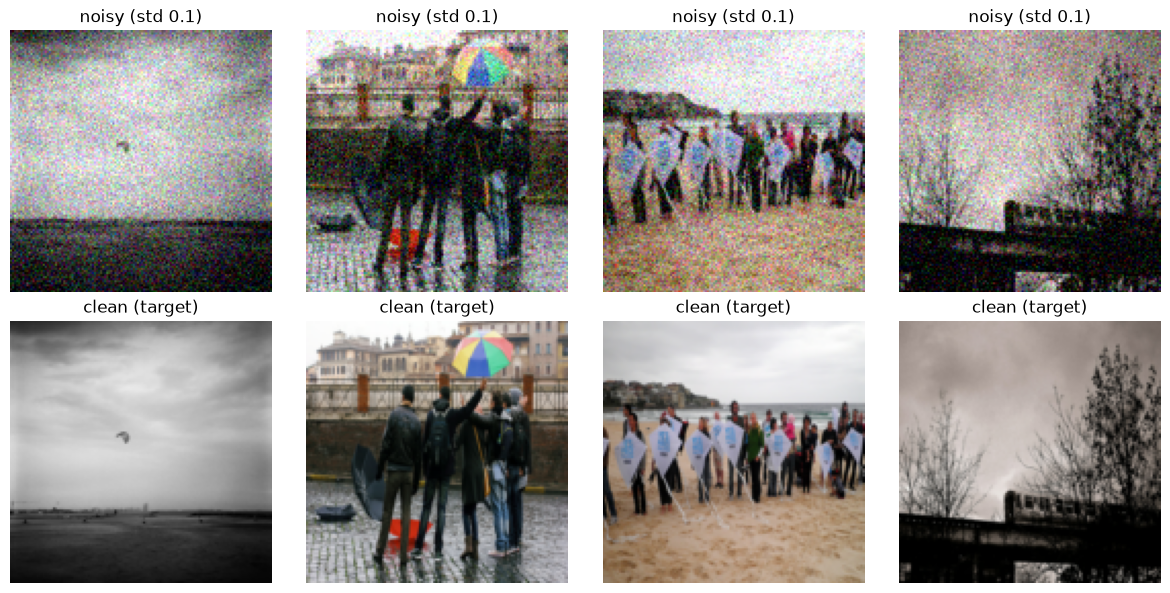

In [10]:
n_show = 4
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 6))
for i in range(n_show):
    axes[0, i].imshow(noisy[i]); axes[0, i].set_title(f"noisy (std {NOISE_STD})")
    axes[1, i].imshow(clean[i]); axes[1, i].set_title("clean (target)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. The models

Both models take the noisy image (128x128x3, in [0, 1]) and output an image of the same shape. The last layer is a sigmoid so that the output stays in [0, 1], like the clean target. Loss: **MSE** (mean of the squared pixel differences between the output and the clean image). Optimizer: **Adam**, learning rate 1e-3.

### 3.1 Baseline: convolutional auto-encoder

- **Encoder:** 3 x (Conv 3x3 + ReLU + MaxPool 2) with 32, 64, 128 filters. The image goes from 128x128 to a 16x16x128 *bottleneck*. The convolutions detect patterns, the pooling halves the size and forces the network to keep only what is useful.
- **Decoder:** 3 x (Conv 3x3 + ReLU + UpSampling 2) with 128, 64, 32 filters (mirror of the encoder). `UpSampling2D` repeats pixels and has no weight: the convolution before it learns the content.
- **Output:** Conv with 3 filters (R, G, B) and a sigmoid.

The bottleneck holds 16x16x128 = 32,768 values for 128x128x3 = 49,152 in the input. The pooling also loses the exact position of the details: the output risks being a bit blurry.

In [11]:
def build_autoencoder():
    """Baseline convolutional auto-encoder: noisy image in, clean image out.

    Encoder: 3 x (Conv 3x3 + ReLU + MaxPool 2) with 32-64-128 filters, which
    compresses 128x128x3 into a 16x16x128 "bottleneck".
    Decoder: 3 x (Conv 3x3 + ReLU + UpSampling 2), then a Conv with 3 filters and a
    sigmoid to get back an RGB image in [0, 1].
    """
    # Same seed as the rest of the project: same initial weights at every run.
    keras.utils.set_random_seed(SEED)

    model = keras.Sequential([
        # No Rescaling layer: make_dataset already gives float32 in [0, 1].
        keras.Input((IMG_SIZE, IMG_SIZE, 3)),

        # Encoder. padding="same" keeps the size, only the pooling halves it.
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 128 -> 64
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 64 -> 32
        keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 32 -> 16 (bottleneck)

        # Decoder, mirror of the encoder (128-64-32 filters).
        # UpSampling2D repeats pixels (no weights), the Conv before it learns the content.
        keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 16 -> 32
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 32 -> 64
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 64 -> 128

        # Sigmoid: the output stays in [0, 1], like the clean target image.
        keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid"),
    ], name="autoencoder")

    # MSE: pixel-by-pixel difference between the output and the clean image.
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

In [12]:
autoencoder = build_autoencoder()
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_6 (UpSampling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_7 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_8 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,955 (1.27 MB)

 Trainable params: 333,955 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Improved model: U-Net (skip connections)

Same network, plus **skip connections**: the output of each encoder block (before its pooling) is concatenated with the decoder features of the **same resolution**. The decoder then has two sources: the deep but coarse content coming from the bottleneck, and the precise details of the encoder. The shortcut also helps the gradient to flow during training.

`Concatenate` stacks the channels side by side, and the next convolution learns what to keep from each source. (A ResNet adds the two sources instead; it needs the same shape and is mostly used to train very deep networks.)

**Risk:** the full-resolution skip also carries the noisy pixels. The network may learn to copy the noise. We do not assume the U-Net is better: it is measured in the comparison.

In [13]:
def build_unet():
    """Same network as build_autoencoder, plus U-Net skip connections.

    Each decoder level receives, next to the up-sampled features, the encoder
    features of the SAME resolution (Concatenate). The decoder can then reuse
    the fine details that the 16x16 bottleneck loses. Risk: the skip at full
    resolution carries the noisy pixels too, so the network may copy the noise:
    this is measured in the comparison, not assumed.
    """
    keras.utils.set_random_seed(SEED)

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))

    # Encoder. c1, c2, c3 are kept (before the pooling) for the skip connections.
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)    # 128x128
    x = keras.layers.MaxPooling2D(2)(c1)                                          # 64
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)         # 64x64
    x = keras.layers.MaxPooling2D(2)(c2)                                          # 32
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)        # 32x32
    x = keras.layers.MaxPooling2D(2)(c3)                                          # 16 (bottleneck)

    # Decoder. After each UpSampling the resolution matches the encoder level c3, c2, c1.
    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 32
    x = keras.layers.Concatenate()([x, c3])                                       # 128 + 128 channels
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 64
    x = keras.layers.Concatenate()([x, c2])                                       # 64 + 64 channels
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 128
    x = keras.layers.Concatenate()([x, c1])                                       # 32 + 32 channels

    outputs = keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="unet")
    # Same loss and optimizer as the baseline: only the skip connections differ.
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

In [14]:
unet = build_unet()
unet.summary()
print(f"parameters: baseline {autoencoder.count_params():,} | U-Net {unet.count_params():,}")

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 64, 64,    │          0 │ conv2d_21[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_9[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 32, 32,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_10… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 16, 16,    │          0 │ conv2d_23[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 16, 16,    │    147,584 │ max_pooling2d_11… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_9     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 32, 32,    │          0 │ up_sampling2d_9[… │
│ (Concatenate)       │ 256)              │            │ conv2d_23[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    147,520 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_10    │ (None, 64, 64,    │          0 │ conv2d_25[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 64, 64,    │          0 │ up_sampling2d_10… │
│ (Concatenate)       │ 128)              │            │ conv2d_22[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 64, 64,    │     36,896 │ concatenate_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_11    │ (None, 128, 128,  │          0 │ conv2d_26[0][0]   │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 128, 128,  │          0 │ up_sampling2d_11… │
│ (Concatenate)       │ 64)               │            │ conv2d_21[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 128, 128,  │      1,731 │ concatenate_5[0]

 Total params: 426,979 (1.63 MB)

 Trainable params: 426,979 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

parameters: baseline 333,955 | U-Net 426,979


## 4. Training

### What "doing nothing" scores

Before training anything, we measure the error of the **noisy input itself** against the clean image. This is the reference: a model that does not get below it is worse than doing nothing, so it is useless. We use the validation set (never the test set) for every decision.

The PSNR (peak signal-to-noise ratio, in dB, higher is better) is computed from the MSE: `PSNR = 10 * log10(1 / MSE)` for images in [0, 1].

In [15]:
# Sum of the squared pixel differences over the whole validation set, then the mean.
sq_err, n_values = 0.0, 0
for noisy_batch, clean_batch in val_ds:
    sq_err += float(tf.reduce_sum(tf.square(noisy_batch - clean_batch)))
    n_values += int(tf.size(clean_batch))
MSE_NOISY = sq_err / n_values
print(f"Validation, noisy input vs clean: MSE {MSE_NOISY:.5f} | PSNR {10 * np.log10(1 / MSE_NOISY):.2f} dB")

Validation, noisy input vs clean: MSE 0.00905 | PSNR 20.43 dB


### Training settings

- **Input / target:** the noisy image is the input, the clean image is the target.
- **Loss:** MSE, **optimizer:** Adam (learning rate 1e-3), **batch size:** 16 (`BATCH_SIZE`, same for every model because the validation noise depends on it).
- **Epoch, batch, iteration:** one epoch is one pass over the 6,995 training photos; with batches of 16 that is 438 iterations (weight updates) per epoch. The noise is redrawn at each epoch.
- **Early stopping:** we stop when the validation loss has not improved for `PATIENCE` epochs and go back to the best weights. It limits overfitting without choosing the number of epochs by hand (`MAX_EPOCHS` is only an upper bound).
- **Saved files:** the best weights are written to `models/` with a timestamp in the name (never overwritten), next to the loss history. `train_or_load` reloads the latest weights of a model instead of training again, so the notebook can be re-run quickly. Set `RETRAIN = True` to train again.

In [16]:
import json
import time
from datetime import datetime
from pathlib import Path

MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
# 30 epochs were not enough for the baseline (the loss was still decreasing): 60 max, stop after 5 epochs without improvement.
MAX_EPOCHS, PATIENCE = 60, 5
RETRAIN = False   # True: ignore the saved weights and train again


def train_or_load(name, model):
    """Train `model` (or reload its latest saved weights) and return its loss history."""
    # The timestamp format sorts alphabetically, so the last file is the most recent.
    saved = sorted(MODELS.glob(f"d2_{name}_*.weights.h5"))
    if saved and not RETRAIN:
        weights = saved[-1]
        model.load_weights(weights)
        history = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_history.json")).read_text())
        print(f"Reloaded {weights.name} ({len(history['loss'])} epochs), no training.")
        return history

    # New file name at every training: an old result is never overwritten.
    weights = MODELS / f"d2_{name}_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        # Writes the best weights as soon as they are found: nothing is lost if the run is interrupted.
        keras.callbacks.ModelCheckpoint(weights, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    fit = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2,
                    shuffle=False)   # the dataset is already shuffled by tf.data; avoids a Keras warning
    history = {k: [float(v) for v in vals] for k, vals in fit.history.items()}
    weights.with_name(weights.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(history))
    print(f"Trained {len(history['loss'])} epochs in {time.time() - t0:.0f} s, best weights in {weights.name}")
    return history


def plot_loss(history, title):
    """Train and validation loss per epoch, with the error of the noisy input as a reference."""
    epochs = np.arange(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"]))
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["loss"], marker="o", label="train")
    plt.plot(epochs, history["val_loss"], marker="o", label="validation")
    plt.axhline(MSE_NOISY, color="gray", linestyle="--", label="noisy input (doing nothing)")
    plt.axvline(best + 1, color="green", alpha=0.4, label=f"best epoch ({best + 1})")
    plt.yscale("log")   # the loss spans a large range at the beginning
    plt.xlabel("epoch"); plt.ylabel("MSE (log scale)"); plt.title(title)
    plt.grid(alpha=0.3); plt.legend()
    plt.show()

### 4.1 Baseline auto-encoder

Reloaded d2_autoencoder_20261013_214818.weights.h5 (50 epochs), no training.


/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


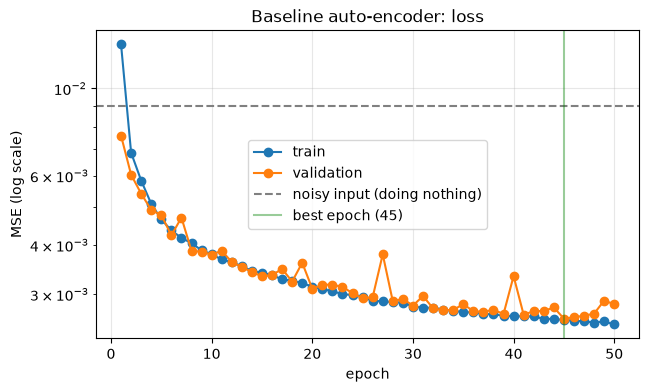

In [17]:
history_ae = train_or_load("autoencoder", autoencoder)
plot_loss(history_ae, "Baseline auto-encoder: loss")

### 4.2 U-Net

Same settings as the baseline (loss, optimizer, batch size, `MAX_EPOCHS`, `PATIENCE`): the only difference between the two runs is the skip connections.

/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


Reloaded d2_unet_20261013_215357.weights.h5 (60 epochs), no training.


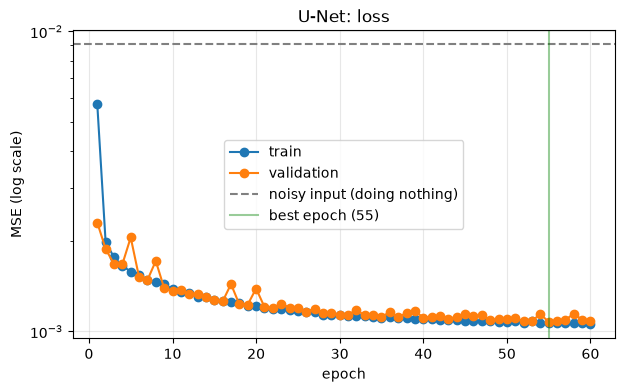

In [18]:
history_unet = train_or_load("unet", unet)
plot_loss(history_unet, "U-Net: loss")